**Bitácora · Day 3 PrefixSpan (letrozole)**

- **v1** `Day3_prefixspan_v1`  
  PrefixSpan on group tags, visits kept; v1 NMF components. *Files:* `patterns_letrozole.json`, `nmf_k8_letrozole.npz`
- **v2** `Day3_prefixspan_v2` ← **this notebook**  
  Motifs per visit-pruned NMF component; Table 1, stability (2b), matched plots. *Files:* `nmf_k8_letrozole_v2.npz`
- **v3 hybrid** `Day3_prefixspan_v3_hybrid` (2026-10-06)  
  v2 + deterministic ties, held-out pass rate, same-day flag, Excel export. *Files:* `nmf_k8_letrozole_v2.npz`, `Day3_v3_hybrid_top3_patterns_table.xlsx`
- **v3 concept** `Day3_prefixspan_v3_concept` (2026-10-07)  
  Hybrid on concept-level tokens; k=7 bundles named directly (v2 matching only for other k). *Files:* `nmf_k8_letrozole_v3.npz`, `Day3_v3_concept_final_table_letrozole_k{K}.xlsx`, `token_map_letrozole_concept.csv`

# Day 3 · v2 — sequence motifs inside the visit-pruned NMF components (letrozole)

**Today's goal:** mine ordered motifs *within each of the 8 NMF components* from `Day1_nmf_v2`,
on event streams with every visit event removed (care-driven bias). Same PrefixSpan as v1; what
changes is the input (no visit tokens) and the groups (v2 components, not v1's).

Why: in v1 the most common tokens were pharmacy / office visits, so most motifs were chains like
`pharmacy__visit -> letrozole -> pharmacy__visit`. Day 1 v2 told us *which codes co-occur* once
visits are gone; Day 3 v2 asks *in what order*, and whether the fertility vs oncology split of
letrozole shows up as different pathways rather than different care settings.

In [1]:
import os
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option('display.width', 150); pd.set_option('display.max_columns', 40)
import ethos_omop as eo

OUT_DIR = "../../inputs/letrozole_cohort/"   # matches Day 1's extract_cohort() output dir
DOMAINS = ['Visit', 'Condition', 'Drug', 'Procedure', 'Measurement']   # Visit stays in the load so we can show before vs after

if not os.path.isdir(OUT_DIR):
    raise FileNotFoundError(
        f"{OUT_DIR}/ not found. Run Day 1's eo.extract_cohort(...) (or "
        f"eo.extract_omop(...) with OUT_DIR='omop_extract') first, or "
        f"python make_demo_extract.py for a synthetic stand-in.")

concept  = eo.load_concept(OUT_DIR)
codesets = eo.build_codesets(concept, verbose=False)
raw      = eo.load_events(OUT_DIR, domains=DOMAINS)
person   = eo.load_person(OUT_DIR)
truth    = eo.load_truth(OUT_DIR)                   # None against real data

# v2: drop every visit event BEFORE tagging (same rule as Day1_nmf_v2): a row is a visit if its
# domain OR vocabulary is "visit".
is_visit = (raw['domain'].astype(str).str.lower().eq('visit')
            | raw['vocabulary_id'].astype(str).str.lower().eq('visit'))
visit_ids = set(raw.loc[is_visit, 'concept_id'])
events   = eo.tag_events(raw[~is_visit].reset_index(drop=True), codesets)

tbl = (pd.DataFrame({'before': raw['domain'].value_counts(), 'after': events['domain'].value_counts()})
         .fillna(0).astype(int))
tbl.loc['TOTAL'] = [len(raw), len(events)]
tbl['removed_%'] = ((1 - tbl['after'] / tbl['before']) * 100).round(1)
print("events per domain, BEFORE vs AFTER visit pruning")
print(tbl.to_string())
print(f"\npatients: {raw.person_id.nunique():,} -> {events.person_id.nunique():,}")
print("curated codeset tags on visit concepts (now absent):",
      sorted(t for t, ids in codesets.items() if set(ids) & visit_ids) or "none")
if not (events['tag'] == 'letrozole').any():
    print("WARNING: the cohort anchor `letrozole` has no events after pruning")
del raw                                              # free memory

print(f"\nevents {events.shape}   patients {events.person_id.nunique()}")
print(f"codeset coverage: {events.in_codeset.mean():.1%} of events carry a clinical tag")
print(f"truth labels: {'present (DEMO extract)' if truth is not None else 'ABSENT (real data)'}")
events.head(6)

events per domain, BEFORE vs AFTER visit pruning
              before    after  removed_%
domain                                  
Condition     458033   458033        0.0
Drug          523552   523552        0.0
Measurement   339167   339167        0.0
Procedure     390455   390455        0.0
Visit         709880        0      100.0
TOTAL        2421087  1711207       29.3

patients: 5,238 -> 5,238
curated codeset tags on visit concepts (now absent): none

events (1711207, 11)   patients 5238
codeset coverage: 8.9% of events carry a clinical tag
truth labels: ABSENT (real data)


,person_id,concept_id,event_date,domain,vocabulary_id,concept_code,concept_name,concept_class_id,token,tag,in_codeset
0,1949,40223740,2019-07-01,Drug,RxNorm,999717,potassium nitrate 0.05 MG/MG / sodium fluoride...,Branded Drug,RxNorm/999717,potassium_nitrate_00__branded_drug__40223740,False
1,1949,40223740,2019-07-01,Drug,RxNorm,999717,potassium nitrate 0.05 MG/MG / sodium fluoride...,Branded Drug,RxNorm/999717,potassium_nitrate_00__branded_drug__40223740,False
2,1949,40223740,2019-09-25,Drug,RxNorm,999717,potassium nitrate 0.05 MG/MG / sodium fluoride...,Branded Drug,RxNorm/999717,potassium_nitrate_00__branded_drug__40223740,False
3,1949,40223740,2019-09-25,Drug,RxNorm,999717,potassium nitrate 0.05 MG/MG / sodium fluoride...,Branded Drug,RxNorm/999717,potassium_nitrate_00__branded_drug__40223740,False
4,1949,40223740,2019-12-27,Drug,RxNorm,999717,potassium nitrate 0.05 MG/MG / sodium fluoride...,Branded Drug,RxNorm/999717,potassium_nitrate_00__branded_drug__40223740,False
5,1949,40223740,2019-12-27,Drug,RxNorm,999717,potassium nitrate 0.05 MG/MG / sodium fluoride...,Branded Drug,RxNorm/999717,potassium_nitrate_00__branded_drug__40223740,False


## Mini Table 1 · letrozole cohort by confirmed breast-cancer diagnosis

**Confirmed breast cancer** = a patient with *any* condition row matching **ICD-9 174.x**, **ICD-10 C50.x** or
**SNOMED concept 4162253** (primary malignant neoplasm of breast). Everyone else is "no breast cancer dx".
The extract keeps standard concepts only, so ICD codes are not in `concept.csv`; they are read from the raw
`condition_source_value` column, which `load_events()` drops. The `breast_cancer` tag used elsewhere in this notebook
is the narrower, name-matched codeset, so the two counts differ (see the "meets" rows).

In [13]:
cond = pd.read_csv(os.path.join(OUT_DIR, 'master_condition_occurrence.csv'),
                   usecols=['person_id', 'condition_concept_id', 'condition_source_value', 'condition_start_date'],
                   dtype={'condition_source_value': str}, parse_dates=['condition_start_date'])
src  = cond.condition_source_value.fillna('').str.upper().str.replace('.', '', regex=False)   # 'C50.911' -> 'C50911'
crit = {'ICD-9 174.x':     src.str.startswith('174'),
        'ICD-10 C50.x':    src.str.startswith('C50'),
        'SNOMED 4162253':  cond.condition_concept_id.eq(4162253)}

cohort_ids = set(events.person_id)
case_mask  = np.logical_or.reduce(list(crit.values()))
case_ids   = set(cond.person_id[case_mask]) & cohort_ids
groups = {'Overall': cohort_ids,
          'No breast cancer dx': cohort_ids - case_ids,
          'Confirmed breast cancer dx': case_ids}

lz        = eo.index_dates(events, 'letrozole').set_index('person_id')['index_date']
age_yrs   = (lz - person.set_index('person_id')['birth_date'].reindex(lz.index)).dt.days / 365.25
female    = set(person.loc[person.gender.astype(str).str.upper().eq('FEMALE'), 'person_id'])
first_dx  = cond[case_mask].groupby('person_id').condition_start_date.min()       # first confirmed dx per patient
crit_ids  = {k: set(cond.person_id[m]) & cohort_ids for k, m in crit.items()}

# diagnosis-related rows: curated codesets whose events are conditions
ev_c      = events[events.tag.isin(eo.CODESETS)]
tag_dom   = ev_c.groupby('tag').domain.agg(lambda s: s.mode().iat[0])
DX_TAGS   = sorted(tag_dom.index[tag_dom == 'Condition'])
has       = {t: set(ev_c.loc[ev_c.tag == t, 'person_id']) for t in DX_TAGS}

def describe(name, ids):
    n   = len(ids)
    npc = lambda k: f"{k} ({k / n:.1%})" if n else "0"
    a   = age_yrs.reindex(list(ids))
    row = {'N (% of cohort)': f"{n} ({n / len(cohort_ids):.1%})",
           'Age at first letrozole, mean (SD)': f"{a.mean():.1f} ({a.std():.1f})" if n else '-',
           'Female, n (%)': npc(len(ids & female))}
    for k, s in crit_ids.items():
        row[f'Meets {k}, n (%)'] = npc(len(ids & s))
    before = [first_dx.get(p) is not None and first_dx[p] < lz[p] for p in ids]
    row['Dx recorded before first letrozole, n (%)'] = npc(sum(before)) if name == 'Confirmed breast cancer dx' else '-'
    for t in DX_TAGS:
        row[f'{t}, n (%)'] = npc(len(ids & has[t]))
    return row

table1 = pd.DataFrame({name: describe(name, ids) for name, ids in groups.items()})
display(table1)
print("curated diagnosis codesets shown:", DX_TAGS)

,Overall,No breast cancer dx,Confirmed breast cancer dx
N (% of cohort),5238 (100.0%),5168 (98.7%),70 (1.3%)
"Age at first letrozole, mean (SD)",35.2 (6.9),34.9 (6.6),51.8 (8.2)
"Female, n (%)",5238 (100.0%),5168 (100.0%),70 (100.0%)
"Meets ICD-9 174.x, n (%)",0 (0.0%),0 (0.0%),0 (0.0%)
"Meets ICD-10 C50.x, n (%)",70 (1.3%),0 (0.0%),70 (100.0%)
"Meets SNOMED 4162253, n (%)",49 (0.9%),0 (0.0%),49 (70.0%)
"Dx recorded before first letrozole, n (%)",-,-,43 (61.4%)
"breast_cancer, n (%)",49 (0.9%),0 (0.0%),49 (70.0%)
"dcis, n (%)",20 (0.4%),5 (0.1%),15 (21.4%)
"infertility, n (%)",1995 (38.1%),1993 (38.6%),2 (2.9%)


curated diagnosis codesets shown: ['breast_cancer', 'dcis', 'infertility', 'menopause_status', 'pcos', 'pregnancy_outcome', 't2dm']


In [2]:
seqs = eo.sequences(events, col='tag', dedup_same_day=True, collapse_repeats=True)
pids = sorted(seqs)
db   = [seqs[p] for p in pids]

print("example timeline:")
print(' -> '.join(db[1][:12]))
print("\nmedian sequence length:", int(np.median([len(s) for s in db])))

example timeline:
7_ethinyl_estradiol___branded_pack__19129357 -> nitrofurantoin_macro__clinical_drug__46234346 -> 7_ethinyl_estradiol___branded_pack__19129357 -> hydrocortisone_0025___clinical_drug__19002273 -> 7_ethinyl_estradiol___branded_pack__19129357 -> omeprazole_20_mg_del__clinical_drug__19019418 -> 7_ethinyl_estradiol___branded_pack__19129357 -> sarscov2_covid19_vac__clinical_drug__37003436 -> oseltamivir_75_mg_or__clinical_drug__1799141 -> letrozole -> venipuncture_for_blo__procedure__4102442 -> drug_tests_presumpti__cpt4__42628602

median sequence length: 174


### The preprocessing decisions, restated

The first two live in `eo.sequences()` and both are arbitrary:

1. **Same-day ties.** Claims carry a date, not a timestamp, so `DOMAIN_ORDER` breaks ties.
   Visit, condition, procedure, measurement, drug, observation.
2. **Refill collapsing.** Consecutive repeats of the same tag become one token, otherwise
   every pattern is `metformin -> metformin -> metformin`. Chronicity is real signal, so
   capture it as a separate feature — fill count, days supply — not as sequence position.
3. **Visits are not in the sequence at all (v2).** In v1 pharmacy visits were the most common
   tokens (`pharmacy__visit__38004338`) and made every motif list a chain of pharmacy / office
   visits. Dropping them removes that care-setting bias. Visit-borne signal is invisible here by
   construction (Day 1 v2 found no curated tag sitting on a visit concept, so no codeset tag is lost).

## 1 · PrefixSpan, implemented

In [3]:
import collections

def prefixspan(db, min_sup, max_len=4):
    """Minimal PrefixSpan over single-item sequences.

    db      : list of lists of tokens
    min_sup : minimum number of sequences containing the pattern
    returns : DataFrame of (pattern, support, support_pct)
    """
    n, results = len(db), []

    def scan(projected, prefix):
        counts = collections.Counter()
        for seq in projected:
            for item in set(seq):                   # count each sequence once
                counts[item] += 1
        for item, c in counts.items():
            if c < min_sup:
                continue
            new_prefix = prefix + [item]
            results.append((tuple(new_prefix), c))
            if len(new_prefix) >= max_len:
                continue
            # project: keep the suffix after the FIRST occurrence of item
            nxt = [seq[seq.index(item) + 1:] for seq in projected if item in seq]
            if nxt:
                scan(nxt, new_prefix)

    scan([list(s) for s in db], [])
    return (pd.DataFrame(results, columns=['pattern', 'support'])
              .assign(support_pct=lambda d: (d.support / n * 100).round(1)))

## 2 · Discriminative mining — motifs per NMF component

Raw support finds whatever is common, which is mostly ambient care. What you want is patterns
common **inside** a group and rare **outside** it. Here the groups are the **8 NMF components of
`Day1_nmf_v2`** (k=8, visits pruned; every component solid, bootstrap cosine 0.988-0.996, ARI 0.876).

What the v2 components look like (top codes and the Day 1 v2 fertility / oncology cross-tab):

- **Fertility, four bundles:** treatment c2 (gonadotropins, GnRH agonist, ART), carrier screening c4,
  prenatal labs c7 (ABO / Rh), pregnancy outcome c0.
- **Oncology, one bundle: c5.** Its top codes are peri-operative (ondansetron / ketorolac injectables,
  fentanyl, propofol), but it holds 62% of the breast-cancer-only patients. It is small, so read it as a lower bound.
- **Background, c1, c3, c6:** acute-infection pharmacy (antibiotics, steroids, NSAIDs), preventive
  labs (lipids, HbA1c, TSH, vitamin D), therapeutic / manual procedures (PT, chiropractic).
  Without visit tokens c1 is no longer "pharmacy visits" but the drugs themselves.

Day 3 asks what order those codes come in, per component. The draft triage (needs underwriter
review) is printed next to each component below.

In [4]:
from scipy import sparse as sp
from sklearn.decomposition import NMF

# Rebuild Day1_nmf_v2's k=8 NMF exactly (same prevalence floor, same anchor drop, same NMF_KW; nndsvd
# init is deterministic), so component numbers match its loadings tables. Day1_nmf_v2 writes the
# cache file below; if it is missing or stale (different extract / floor) this cell fits and saves it.
n_pat      = events.person_id.nunique()
N_TRAIN    = min(20_000, int(0.6 * n_pat))
MIN_PAT    = int(np.ceil(5 * n_pat / N_TRAIN))
prev_pat   = events.groupby('tag').person_id.nunique()
KEEP_TAGS  = prev_pat.index[prev_pat >= MIN_PAT]
nmf_cols   = KEEP_TAGS.drop('letrozole')                 # cohort anchor, 100% prevalence
CACHE      = "nmf_k8_letrozole_v2.npz"                   # same file Day1_nmf_v2 writes (v1's file is untouched)

z = np.load(CACHE) if os.path.exists(CACHE) else None
if z is not None and (set(z['cols']) != set(nmf_cols)
                      or set(z['pids']) != set(events.person_id.unique())):
    z = None                                             # stale: different extract / floor

if z is not None:
    H   = pd.DataFrame(z['H'], columns=z['cols'])
    lab = pd.Series(z['labels'], index=z['pids'])
    print(f"NMF k=8 loaded from {CACHE}")
else:
    Xb   = eo.bag_of_codes(events[events.tag.isin(KEEP_TAGS)], min_count=1)
    Xs   = sp.csr_matrix(Xb[nmf_cols].to_numpy()).astype(float)
    nmf  = NMF(n_components=8, init='nndsvd', random_state=0, max_iter=2000, tol=1e-4).fit(Xs)
    H    = pd.DataFrame(nmf.components_, columns=nmf_cols)
    lab  = pd.Series(nmf.transform(Xs).argmax(1), index=Xb.index)
    np.savez(CACHE, H=H.to_numpy(), cols=np.array(H.columns, dtype=str), pids=lab.index.to_numpy(),
             labels=lab.to_numpy())
    print(f"NMF k=8 fitted, cached to {CACHE}")

comp = lab.reindex(pids).fillna(-1).astype(int).to_numpy()   # aligned with db / pids

# Names read off the Day1_nmf_v2 top-codes and cross-tab; the assert fails loudly if numbering drifted.
# DRAFT triage (carried over from v1) -- needs underwriter review.
FERT, ONCO, BG = 'fertility', 'oncology', 'background'
MANUAL, EXPLAINED, UNCLEAR = ('manual UW review (stage, treatment status, adjuvant letrozole)',
                              'routine (letrozole explained by fertility)',
                              'routine, indication unclear (use other evidence)')
COMP = {0: ('pregnancy_outcome',   'pregnancy outcome',                                         FERT, EXPLAINED),
        1: ('amoxicillin_875',     'acute-infection pharmacy (antibiotics, steroids, NSAIDs)',    BG,   UNCLEAR),
        2: ('gonadotropin_drug',   'fertility treatment (high-intensity: ART, gonadotropins)',    FERT, EXPLAINED),
        3: ('lipid_panel',         'preventive labs (+ milder PCOS / ovarian-reserve workup)',    BG,   UNCLEAR),
        4: ('cftr',                'preconception carrier screening',                             FERT, EXPLAINED),
        5: ('ondansetron_injectio','peri-operative / oncology (breast_cancer loads here)',        ONCO, MANUAL),
        6: ('therapeutic_procedur','therapeutic / manual procedures (PT, chiropractic)',          BG,   UNCLEAR),
        7: ('abo_typing',          'prenatal labs (ABO / Rh)',                                    FERT, EXPLAINED)}
for c, (prefix, *_) in COMP.items():
    top = H.iloc[c].idxmax()
    assert top.startswith(prefix), (f"component {c} top code is {top!r}, expected {prefix!r}* -- "
                                    f"numbering differs from Day1_nmf_v2; re-read its top codes and fix COMP")

print(f"{'comp':>4} {'n':>5} {'%':>5}  {'group':<10} name")
for c, (_, name, grp, _) in COMP.items():
    n = int((comp == c).sum())
    print(f"{c:>4} {n:>5} {n / len(comp) * 100:5.1f}  {grp:<10} {name}")
print("\nc5 n is a LOWER BOUND: oral endocrine drugs partly load on c1, so some oncology patients argmax there.")

NMF k=8 loaded from nmf_k8_letrozole_v2.npz
comp     n     %  group      name
   0   622  11.9  fertility  pregnancy outcome
   1  1600  30.5  background acute-infection pharmacy (antibiotics, steroids, NSAIDs)
   2   641  12.2  fertility  fertility treatment (high-intensity: ART, gonadotropins)
   3   760  14.5  background preventive labs (+ milder PCOS / ovarian-reserve workup)
   4   269   5.1  fertility  preconception carrier screening
   5   406   7.8  oncology   peri-operative / oncology (breast_cancer loads here)
   6   349   6.7  background therapeutic / manual procedures (PT, chiropractic)
   7   591  11.3  fertility  prenatal labs (ABO / Rh)

c5 n is a LOWER BOUND: oral endocrine drugs partly load on c1, so some oncology patients argmax there.


In [5]:
from joblib import Parallel, delayed

def contains(seq, pat):
    it = iter(seq)
    return all(x in it for x in pat)

def discriminative(mask, candidates, sequences_db=None, min_in=0.12):
    sdb = sequences_db if sequences_db is not None else db
    out = []
    for p in candidates:
        h = np.array([contains(s, p) for s in sdb])
        si, so = h[mask].mean(), h[~mask].mean()
        if si >= min_in:
            out.append({'pattern': ' -> '.join(p), 'sup_in': round(si, 3),
                        'sup_out': round(so, 3), 'lift': round((si + .01) / (so + .01), 1)})
    if not out:
        return pd.DataFrame(columns=['pattern', 'sup_in', 'sup_out', 'lift'])
    return pd.DataFrame(out).sort_values('lift', ascending=False).reset_index(drop=True)

def _component_job(sdb_in, sdb_out, rel_sup, max_cand):
    """One component: LOCAL mining on its own patients, then lift vs the out-sample.
    Takes only its own slices, so it ships cheaply to a worker process."""
    pats_c = prefixspan(sdb_in, max(3, int(rel_sup * len(sdb_in))), max_len=4)
    pats_c = pats_c[pats_c.pattern.map(len) >= 3].sort_values('support', ascending=False).head(max_cand)
    sdb    = sdb_in + sdb_out
    mask   = np.arange(len(sdb)) < len(sdb_in)
    return discriminative(mask, [tuple(p) for p in pats_c.pattern], sequences_db=sdb, min_in=rel_sup)

def component_motifs(rel_sup=0.15, max_cand=100, n_out=1500, seed=0, n_jobs=None):
    """All components in parallel (they are independent), like Day 1's k-sweep."""
    n_jobs = n_jobs or min(len(COMP), max(1, (os.cpu_count() or 2) - 2))   # leave 2 cores free
    jobs = []
    for c in COMP:
        idx_in  = np.flatnonzero(comp == c)
        idx_out = np.flatnonzero(comp != c)
        idx_out = np.random.default_rng(seed).choice(idx_out, min(n_out, len(idx_out)), replace=False)
        jobs.append(delayed(_component_job)([db[i] for i in idx_in], [db[i] for i in idx_out],
                                            rel_sup, max_cand))
    return dict(zip(COMP, Parallel(n_jobs=n_jobs, verbose=5)(jobs)))

# the local mining is the point: a global 4% floor would bury the 5% components entirely
motifs = component_motifs()
for c, (_, name, grp, triage) in COMP.items():
    d = motifs[c]
    print(f"\n===== component {c} [{grp}]: {name}  (n={(comp == c).sum()})")
    print(f"      draft triage: {triage}")
    if len(d):
        display(d.head(4))
    else:
        print("  no ordered pattern of length >= 3 reaches the in-component support floor")

[Parallel(n_jobs=8)]: Using backend LokyBackend with 8 concurrent workers.
[Parallel(n_jobs=8)]: Done 3 out of 8 | elapsed:   19.7s remaining:   32.8s
[Parallel(n_jobs=8)]: Done 5 out of 8 | elapsed:   42.0s remaining:   25.2s



===== component 0 [fertility]: pregnancy outcome  (n=622)
      draft triage: routine (letrozole explained by fertility)


[Parallel(n_jobs=8)]: Done 8 out of 8 | elapsed:  2.5min finished


,pattern,sup_in,sup_out,lift
0,immunization_adminis__cpt4__2213418 -> active_...,0.473,0.060,6.9
1,immunization_adminis__cpt4__2213418 -> ultraso...,0.479,0.063,6.7
2,active_or_passive_im__procedure__4132855 -> ul...,0.487,0.065,6.7
3,letrozole -> immunization_adminis__cpt4__22134...,0.611,0.089,6.3



===== component 1 [background]: acute-infection pharmacy (antibiotics, steroids, NSAIDs)  (n=1600)
      draft triage: routine, indication unclear (use other evidence)


...

,pattern,sup_in,sup_out,lift
0,comprehensive_metabo__procedure__3661905 -> co...,0.581,0.044,10.9
1,venipuncture_for_blo__procedure__4102442 -> co...,0.552,0.048,9.7
2,venipuncture_for_blo__procedure__4102442 -> co...,0.584,0.060,8.5
3,complete_blood_count__procedure__4319466 -> co...,0.537,0.093,5.3



===== component 6 [background]: therapeutic / manual procedures (PT, chiropractic)  (n=349)
      draft triage: routine, indication unclear (use other evidence)


,pattern,sup_in,sup_out,lift
0,therapeutic_procedur__cpt4__2314284 -> therape...,0.418,0.047,7.5
1,manual_therapy_techn__cpt4__2314290 -> therape...,0.415,0.048,7.3
2,cervical_somatic_dys__clinical_finding__421354...,0.421,0.049,7.3
3,therapeutic_procedur__cpt4__2314284 -> therape...,0.473,0.057,7.2



===== component 7 [fertility]: prenatal labs (ABO / Rh)  (n=591)
      draft triage: routine (letrozole explained by fertility)


,pattern,sup_in,sup_out,lift
0,infectious_agent_ant__cpt4__2213087 -> rh_bloo...,0.587,0.071,7.4
1,infectious_agent_ant__cpt4__2213087 -> rbc_ant...,0.597,0.072,7.4
2,infectious_agent_ant__cpt4__2213087 -> rbc_ant...,0.604,0.075,7.2
3,infectious_agent_ant__cpt4__2213087 -> rbc_ant...,0.677,0.091,6.8


Each component now has **candidate motifs attached** — an ordered sequence, not just a set of
prevalent codes. Things to check:

- Does **c5** read as a cancer-treatment path (workup -> surgery / chemo -> endocrine drug)? Without
  visits, the peri-operative injectables carry the "surgery happened" step on their own.
- Do the fertility bundles (c0, c2, c4, c7) read as distinct stages — screening, stimulation, pregnancy,
  prenatal labs — rather than one blob?
- Do the background bundles (c1, c3, c6) stay generic, or reveal a hidden indication now that the
  pharmacy-visit chains are gone?

### A second lens: the Day 1 fertility / oncology probe

`weak_labels()` gives a direct, rule-based split of the indication, built from corroborating
co-evidence only. It is a probe, not the structure: it labels only part of the cohort, and
oncology is tiny next to fertility (see the counts printed below), so the eight components
above are the primary view and this is a cross-check.

Caveat: the probe labels come from `FERTILITY_TAGS` / `ONCOLOGY_TAGS`, so a motif made of those
same tags partly rediscovers the label rule. Read the motifs that *add* something around them.

In [6]:
weak = eo.weak_labels(events)
wl   = weak.set_index('person_id').weak_label

# Every patient here has letrozole by cohort construction, so no filtering needed. Still use
# LOCAL mining: a global 4% threshold is tuned for the full mixed cohort, and the smaller
# indication subgroup would be buried under it.
y_lz = np.array([wl.get(p, 'unlabelled') for p in pids])
print("letrozole patients:", len(db),
      "  labelled:", int((y_lz != 'unlabelled').sum()),
      "  ", dict(zip(*np.unique(y_lz, return_counts=True))))

pats_lz = prefixspan(db, max(3, int(0.08 * len(db))), max_len=4)
C_lz = [tuple(p) for p in pats_lz[pats_lz.pattern.map(len) >= 3]
        .sort_values('support', ascending=False).head(60).pattern]

for g in ['fertility', 'oncology']:
    print(f"\n=== {g} indication")
    display(discriminative(y_lz == g, C_lz, sequences_db=db, min_in=0.10).head(4))

letrozole patients: 5238   labelled: 3835   both-evidence (dropped): 484   no-evidence (dropped): 919
letrozole patients: 5238   labelled: 3835    {np.str_('fertility'): np.int64(3776), np.str_('oncology'): np.int64(59), np.str_('unlabelled'): np.int64(1403)}

=== fertility indication


,pattern,sup_in,sup_out,lift
0,venipuncture_for_blo__procedure__4102442 -> ov...,0.409,0.205,2.0
1,venipuncture_for_blo__procedure__4102442 -> ov...,0.356,0.187,1.9
2,ovarian_reserve_test -> venipuncture_for_blo__...,0.386,0.204,1.9
3,venipuncture_for_blo__procedure__4102442 -> ve...,0.347,0.190,1.8



=== oncology indication


,pattern,sup_in,sup_out,lift
0,letrozole -> letrozole -> letrozole,0.610,0.397,1.5
1,venipuncture_for_blo__procedure__4102442 -> co...,0.356,0.296,1.2
2,venipuncture_for_blo__procedure__4102442 -> ve...,0.322,0.298,1.1
3,venipuncture_for_blo__procedure__4102442 -> le...,0.305,0.281,1.1


## 2b · Are the motifs stable?

Section 2 mined each component **once**, on one fixed sample, so every `lift` above is a single number.
Day 1 asked the same question of the NMF (`nmf_stability`, five split seeds, "solid on 4+ of 5"). Same idea here,
two tiers, because there are two different questions:

1. **Bootstrap — is the *lift number* steady?** Resample the component's patients (and the outside sample) with
   replacement 1,000 times and recompute `sup_in`, `sup_out`, `lift` for the same candidate motifs. Gives a 95%
   range for lift. Cheap: no re-mining.
2. **Split seeds — would the *motif itself* be found again?** Split each component's patients 50 / 50 at random.
   Mine on one half, score on the held-out half, repeat for 5 seeds. A motif counts as **replicated** in a split if
   it is nominated on the train half **and** still reaches the support floor and `lift >= MIN_LIFT` on the
   held-out half. Different seeds can nominate different candidates, so this also tests the candidate step.

```
 component's patients ──┬─ bootstrap x1000 (same candidates)  ->  lift_lo ... lift_hi
                        └─ split seed s=1..5:  [ train half | held-out half ]
                                                 mine here     score here    ->  splits_found (0-5)
```

Verdict, same words as Day 1: **solid** = replicated in 4+ of 5 splits and `lift_lo >= MIN_LIFT`;
**suggestive** = 3 of 5; otherwise **unstable**.

In [7]:
import collections, time

MIN_LIFT      = 2                       # a motif must be at least this specific to its component
MIN_SPLITS_OK = 4                       # of the 5 split seeds, as in Day 1
REL_SUP, N_OUT, SEED = 0.15, 1500, 0    # the values component_motifs() used above (same candidates, same outside sample)

# Hit matrix, built once and shared by the bootstrap: hits[c][i, j] = does motif i occur in patient j?
# Columns are [in-component patients | the same random outside sample component_motifs() drew].
hits, n_in = {}, {}
for c in COMP:
    cand    = [tuple(p.split(' -> ')) for p in motifs[c].pattern]
    idx_in  = np.flatnonzero(comp == c)
    idx_out = np.flatnonzero(comp != c)
    idx_out = np.random.default_rng(SEED).choice(idx_out, min(N_OUT, len(idx_out)), replace=False)
    sdb     = [db[i] for i in np.concatenate([idx_in, idx_out])]
    hits[c] = np.array([[contains(s, p) for s in sdb] for p in cand], dtype=bool).reshape(len(cand), len(sdb))
    n_in[c] = len(idx_in)
print({c: hits[c].shape for c in COMP})

{0: (100, 2122), 1: (21, 3100), 2: (100, 2141), 3: (100, 2260), 4: (100, 1769), 5: (100, 1906), 6: (100, 1849), 7: (100, 2091)}


In [8]:
B = 1000   # bootstrap draws

def bootstrap_lift(H, n_in, B=B, seed=0):
    """Lift of every motif (rows of H) on B resamples with replacement of the in / out patients."""
    rng        = np.random.default_rng(seed)
    Hin, Hout  = H[:, :n_in], H[:, n_in:]
    n_out      = Hout.shape[1]
    lifts      = np.empty((B, H.shape[0]))
    for b in range(B):
        si = Hin[:,  rng.integers(0, n_in,  n_in)].mean(1)
        so = Hout[:, rng.integers(0, n_out, n_out)].mean(1)
        lifts[b] = (si + .01) / (so + .01)
    return lifts

boot = {}
for c in COMP:
    d = motifs[c].copy()
    if len(d):
        L = bootstrap_lift(hits[c], n_in[c])
        d['lift_lo'], d['lift_hi'] = np.percentile(L, [2.5, 97.5], axis=0).round(1)
        d['p_lift_ok'] = (L >= MIN_LIFT).mean(0).round(2)     # share of draws where lift >= MIN_LIFT
    boot[c] = d
print("bootstrap done:", {c: len(d) for c, d in boot.items()}, "motifs per component")

bootstrap done: {0: 100, 1: 21, 2: 100, 3: 100, 4: 100, 5: 100, 6: 100, 7: 100} motifs per component


In [9]:
SPLIT_SEEDS = (1, 2, 3, 4, 5)   # independent 50 / 50 splits of each component, as in Day 1
MAX_CAND    = 100                # same candidate budget as component_motifs()

def _split_job(sdb_tr, sdb_ho, sdb_out, rel_sup, max_cand):
    """One (component, seed): nominate candidates by mining the TRAIN half, score them on the HELD-OUT half
    against a seed-specific outside sample. discriminative() already drops motifs below the support floor."""
    pats = prefixspan(sdb_tr, max(3, int(rel_sup * len(sdb_tr))), max_len=4)
    pats = pats[pats.pattern.map(len) >= 3].sort_values('support', ascending=False).head(max_cand)
    sdb  = sdb_ho + sdb_out
    mask = np.arange(len(sdb)) < len(sdb_ho)
    return discriminative(mask, [tuple(p) for p in pats.pattern], sequences_db=sdb, min_in=rel_sup)

def split_stability(n_out=N_OUT, n_jobs=None):
    """All (component, seed) jobs in parallel, largest component first so no big job starts last."""
    n_jobs = n_jobs or max(1, (os.cpu_count() or 2) - 2)
    keys, jobs = [], []
    for c in sorted(COMP, key=lambda c: -int((comp == c).sum())):
        idx_in, idx_out = np.flatnonzero(comp == c), np.flatnonzero(comp != c)
        for s in SPLIT_SEEDS:
            rng  = np.random.default_rng(s)
            perm = rng.permutation(idx_in)
            tr, ho = perm[:len(perm) // 2], perm[len(perm) // 2:]
            out  = rng.choice(idx_out, min(n_out, len(idx_out)), replace=False)
            keys.append((c, s))
            jobs.append(delayed(_split_job)([db[i] for i in tr], [db[i] for i in ho],
                                            [db[i] for i in out], REL_SUP, MAX_CAND))
    return dict(zip(keys, Parallel(n_jobs=n_jobs, verbose=5)(jobs)))

t0 = time.perf_counter()
splits = split_stability()
print(f"split-seed mining: {(time.perf_counter() - t0) / 60:.1f} min")

[Parallel(n_jobs=12)]: Using backend LokyBackend with 12 concurrent workers.
[Parallel(n_jobs=12)]: Done 26 out of 40 | elapsed:   40.9s remaining:   22.0s
[Parallel(n_jobs=12)]: Done 35 out of 40 | elapsed:  1.5min remaining:   13.1s


split-seed mining: 2.1 min


[Parallel(n_jobs=12)]: Done 40 out of 40 | elapsed:  2.1min finished


In [10]:
rows, summ = {}, []
for c, (_, name, grp, _) in COMP.items():
    d = boot[c].copy()
    if len(d):
        found = collections.Counter(p for s in SPLIT_SEEDS
                                    for p in splits[(c, s)].loc[splits[(c, s)].lift >= MIN_LIFT, 'pattern'])
        d['splits_found'] = d.pattern.map(lambda p: found.get(p, 0))
        d['verdict'] = np.select([(d.splits_found >= MIN_SPLITS_OK) & (d.lift_lo >= MIN_LIFT),
                                  d.splits_found >= MIN_SPLITS_OK - 1],
                                 ['solid', 'suggestive'], 'unstable')
    rows[c] = d
    v = d.verdict.value_counts() if len(d) else pd.Series(dtype=int)
    summ.append({'comp': c, 'group': grp, 'motifs': len(d), 'solid': int(v.get('solid', 0)),
                 'suggestive': int(v.get('suggestive', 0)), 'unstable': int(v.get('unstable', 0))})
display(pd.DataFrame(summ).set_index('comp'))

SHOW = ['pattern', 'sup_in', 'sup_out', 'lift', 'lift_lo', 'lift_hi', 'splits_found', 'verdict']
with pd.option_context('display.max_colwidth', 110):
    for c, (_, name, grp, _) in COMP.items():
        print(f"\n===== component {c} [{grp}]: {name}  (n={n_in[c]})")
        if len(rows[c]):
            display(rows[c][SHOW].head(4))
        else:
            print("  no motif reached the support floor on the full run")

,group,motifs,solid,suggestive,unstable
comp,,,,,
0,fertility,100,76,9,15
1,background,21,0,0,21
2,fertility,100,34,19,47
3,background,100,39,15,46
4,fertility,100,37,16,47
5,oncology,100,76,5,19
6,background,100,69,14,17
7,fertility,100,80,10,10



===== component 0 [fertility]: pregnancy outcome  (n=622)


,pattern,sup_in,sup_out,lift,lift_lo,lift_hi,splits_found,verdict
0,immunization_adminis__cpt4__2213418 -> active_or_passive_im__procedure__4132855 -> ultrasound_pregnant___c...,0.473,0.060,6.9,5.8,8.2,2,unstable
1,immunization_adminis__cpt4__2213418 -> ultrasound_pregnant___cpt4__2211756 -> pregnancy_outcome,0.479,0.063,6.7,5.6,8.0,3,suggestive
2,active_or_passive_im__procedure__4132855 -> ultrasound_pregnant___cpt4__2211756 -> pregnancy_outcome,0.487,0.065,6.7,5.6,8.0,5,solid
3,letrozole -> immunization_adminis__cpt4__2213418 -> active_or_passive_im__procedure__4132855 -> pregnancy_...,0.611,0.089,6.3,5.4,7.4,5,solid



===== component 1 [background]: acute-infection pharmacy (antibiotics, steroids, NSAIDs)  (n=1600)


,pattern,sup_in,sup_out,lift,lift_lo,lift_hi,splits_found,verdict
0,letrozole -> letrozole -> fluconazole_150_mg_o__clinical_drug__1754996,0.161,0.108,1.4,1.2,1.7,0,unstable
1,fluconazole_150_mg_o__clinical_drug__1754996 -> letrozole -> letrozole,0.162,0.113,1.4,1.2,1.6,0,unstable
2,amoxicillin_875_mg_c__clinical_drug__19115197 -> letrozole -> letrozole,0.181,0.128,1.4,1.2,1.6,0,unstable
3,letrozole -> letrozole -> ondansetron_4_mg_dis__clinical_drug__19005965,0.179,0.123,1.4,1.2,1.7,0,unstable


...

,pattern,sup_in,sup_out,lift,lift_lo,lift_hi,splits_found,verdict
0,comprehensive_metabo__procedure__3661905 -> complete_blood_count__procedure__4319466 -> ondansetron_inject...,0.581,0.044,10.9,9.0,13.5,5,solid
1,venipuncture_for_blo__procedure__4102442 -> comprehensive_metabo__procedure__3661905 -> ondansetron_inject...,0.552,0.048,9.7,7.8,12.1,4,solid
2,venipuncture_for_blo__procedure__4102442 -> complete_blood_count__procedure__4319466 -> ondansetron_inject...,0.584,0.060,8.5,7.0,10.4,5,solid
3,complete_blood_count__procedure__4319466 -> comprehensive_metabo__procedure__3661905 -> comprehensive_meta...,0.537,0.093,5.3,4.5,6.3,2,unstable



===== component 6 [background]: therapeutic / manual procedures (PT, chiropractic)  (n=349)


,pattern,sup_in,sup_out,lift,lift_lo,lift_hi,splits_found,verdict
0,therapeutic_procedur__cpt4__2314284 -> therapeutic_procedur__cpt4__2314284 -> manual_therapy_techn__cpt4__...,0.418,0.047,7.5,6.1,9.3,3,suggestive
1,manual_therapy_techn__cpt4__2314290 -> therapeutic_procedur__cpt4__2314285 -> therapeutic_procedur__cpt4__...,0.415,0.048,7.3,5.9,9.2,3,suggestive
2,cervical_somatic_dys__clinical_finding__4213540 -> somatic_dysfunction___clinical_finding__36713926 -> chi...,0.421,0.049,7.3,5.9,9.2,2,unstable
3,therapeutic_procedur__cpt4__2314284 -> therapeutic_procedur__cpt4__2314284 -> therapeutic_procedur__cpt4__...,0.473,0.057,7.2,5.8,8.8,5,solid



===== component 7 [fertility]: prenatal labs (ABO / Rh)  (n=591)


,pattern,sup_in,sup_out,lift,lift_lo,lift_hi,splits_found,verdict
0,infectious_agent_ant__cpt4__2213087 -> rh_blood_group_typin__procedure__4179840 -> rbc_antibody_detecti__p...,0.587,0.071,7.4,6.3,8.8,4,solid
1,infectious_agent_ant__cpt4__2213087 -> rbc_antibody_detecti__procedure__4231581 -> abo_typing__procedure__...,0.597,0.072,7.4,6.3,8.8,5,solid
2,infectious_agent_ant__cpt4__2213087 -> rbc_antibody_detecti__procedure__4231581 -> serologic_test_for_r__p...,0.604,0.075,7.2,6.1,8.6,5,solid
3,infectious_agent_ant__cpt4__2213087 -> rbc_antibody_detecti__procedure__4231581 -> abo_typing__procedure__...,0.677,0.091,6.8,5.8,7.9,5,solid


How to read the table:

- **`lift_lo` / `lift_hi`** is the bootstrap 95% range. A narrow range far above `MIN_LIFT` means the number is
  steady. A range that dips toward 1 means the motif is only as specific as the particular patients drawn.
- **`splits_found`** counts the seeds (out of 5) where the motif was nominated on the train half and held up on the
  held-out half. 5/5 is a motif that does not depend on which patients were drawn.
- Small components (c4, n=269; c5, n=406) have 135-203 patients per half, so their splits are the noisiest. Treat
  a c5 verdict more cautiously than a c2 one.
- **What this does not test.** The component labels come from the full-data NMF, so this is stability *given* those
  labels (Day 1 v2 already showed them solid, bootstrap ARI 0.876). And the top motifs inside a component are often
  variants of each other (same codes, one extra step); stability does not merge them, so one real pathway can fill
  several rows.
- Only motifs reaching `rel_sup` in-component are tested at all. A true but rare motif never becomes a candidate.

### Conservative vs exploratory run — the knobs side by side

"Conservative" = fewer motifs, each one harder to dismiss as chance. "Exploratory" = more motifs, rarer ones,
more of them noise. The middle column is the original default. **Currently set in this notebook:** `rel_sup` 0.15, `max_cand` 100, bootstrap `B` 1,000; everything else is still the default. Change the value where it is defined, then re-run
from that cell down.

| Knob | Where | Exploratory | **Original default** | Conservative | What it does |
|---|---|---|---|---|---|
| `rel_sup` / `REL_SUP` | mining cell (`component_motifs(rel_sup=...)`) **and** 2b cell 1 | 0.05 | **0.10** | 0.15 - 0.20 | Share of a component's patients that must contain the motif. Lower finds rarer motifs; cost grows fast. |
| `max_len` | `prefixspan(..., max_len=4)` in the mining and split cells | 5 | **4** | 3 | Longest motif. Longer = more specific stories, far fewer patients each, much slower. |
| `max_cand` / `MAX_CAND` | mining cell and 2b split cell | 60 | **60** | 100 | Only this many top-support motifs get a lift score. Larger misses fewer real motifs; it adds no false positives if the filters below are strict. |
| `n_out` / `N_OUT` | mining cell and 2b cell 1 | 1,500 | **1,500** | 3,000 | Outside patients used for `sup_out`. Larger = steadier lift denominator. |
| `MIN_LIFT` | 2b cell 1 | 1.5 | **2** | 3 | How specific to its component a motif must be to count. |
| `B` | 2b bootstrap cell | 200 | **500** | 1,000 | Bootstrap draws. Only narrows the lift range; seconds either way. |
| `SPLIT_SEEDS` | 2b split cell | (1, 2, 3) | **(1, 2, 3, 4, 5)** | (1 ... 10) | Independent 50 / 50 splits. More seeds = a more trustworthy `splits_found`. Runtime scales linearly. |
| `MIN_SPLITS_OK` | 2b verdict cell | 2 of 3 | **4 of 5** | all seeds (5 of 5, 10 of 10) | Splits a motif must replicate in to be `solid`. |
| `lift_lo >= MIN_LIFT` | 2b verdict cell | drop the condition | **kept** | kept | Whether the bootstrap range also has to clear `MIN_LIFT`. |
| probe `min_in` | probe cell (`min_in=0.10`, floor `0.08`) | 0.05 / 0.04 | **0.10 / 0.08** | 0.15 / 0.12 | Same idea as `rel_sup`, for the fertility / oncology probe. Oncology has only 59 labelled patients, so keep it low unless you accept an empty table. |
| graph edge floor | trajectory cell (`max(5, 0.02 * n)`) | 1% | **2%** | 5% | Share of patients an A -> B step needs to be drawn. |

**Runtime.** The default run took about 4.6 min for the mining cell; the slowest piece is the c1 job (1,600
patients). Exploratory settings (`rel_sup` 0.05, `max_len` 5) make that slower by an amount I have not measured.
Conservative mining (`rel_sup` 0.15, `max_len` 3) is faster, but 10 seeds doubles the split-seed cell.

**Keep these in step.** `rel_sup`, `max_cand` and `n_out` appear in the mining cell *and* in section 2b. If they
disagree, the bootstrap scores one candidate set while the splits nominate another, and the two tiers stop being
comparable.

**Reading the two modes.** Run both on the same data. A motif that is `solid` in the conservative run is safe to put
in a catalog. A motif that only appears in the exploratory run is a lead to check with Zack, not a result.

**This is the deliverable.** Ordered patterns, with in-group and out-group support, that read
as sentences. No transformer, no embeddings, no non-commercial licence to negotiate.

## 3 · Interval relations — when order is not enough

Order says "A before B." It does not say "A seven years before B" versus "A two months
before B," which is the actual letrozole discriminator. Allen's interval algebra defines 13
relations; for point events on dates, a **signed gap** carries most of the value.

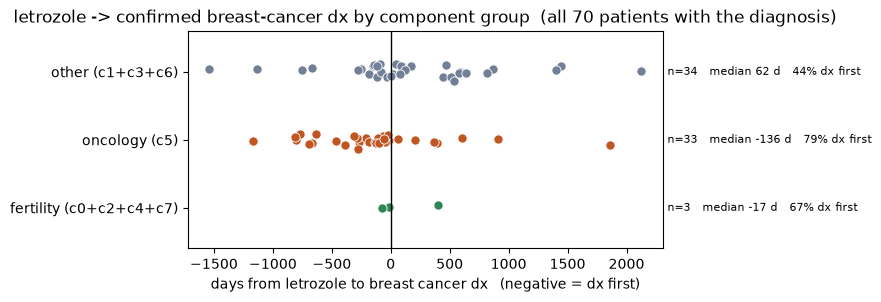

,n,mean,median,dx_first_pct
fertility (c0+c2+c4+c7),3,103.0,-17.0,67.0
oncology (c5),33,-167.0,-136.0,79.0
other (c1+c3+c6),34,162.0,62.0,44.0


In [17]:
# One colour per component group, used by this plot and by the trajectory graph below.
# Group comes from COMP: fertility = c0+c2+c4+c7, oncology = c5, other = c1+c3+c6.
GCOL  = {FERT: '#2f855a', ONCO: '#c05621', BG: '#718096'}
GNAME = {FERT: 'fertility (c0+c2+c4+c7)', ONCO: 'oncology (c5)', BG: 'other (c1+c3+c6)'}
grp_of = pd.Series(comp, index=pids).map(lambda c: COMP[c][2] if c in COMP else np.nan)

# Confirmed breast cancer dx = ICD-10 C50.x or SNOMED 4162253 (ICD-9 174.x finds none here); `first_dx` and `lz`
# come from the mini Table 1 cell above, so the case definition lives in one place.
gaps = pd.concat([lz.rename('t_a'), first_dx.rename('t_b')], axis=1, join='inner')   # patients with letrozole AND a confirmed dx
gaps['days_a_to_b'] = (gaps.t_b - gaps.t_a).dt.days
gaps = gaps.rename_axis('person_id').reset_index()
gaps['group'] = gaps.person_id.map(grp_of)
lanes = [FERT, ONCO, BG]

rng = np.random.default_rng(0)
fig, ax = plt.subplots(figsize=(9.5, 3.2))
for y, g in enumerate(lanes):
    d = gaps.loc[gaps.group == g, 'days_a_to_b']
    ax.scatter(d, y + rng.normal(0, .06, len(d)), s=44, color=GCOL[g], edgecolor='white', linewidth=.6)
    ax.text(1.01, y, f"n={len(d)}   median {d.median():.0f} d   {(d < 0).mean():.0%} dx first" if len(d) else "n=0",
            transform=ax.get_yaxis_transform(), va='center', fontsize=8)
ax.axvline(0, c='k', lw=1)
ax.set_yticks(range(len(lanes))); ax.set_yticklabels([GNAME[g] for g in lanes]); ax.set_ylim(-.6, len(lanes) - .4)
ax.set_xlabel('days from letrozole to breast cancer dx   (negative = dx first)')
ax.set_title(f'letrozole -> confirmed breast-cancer dx by component group  (all {len(gaps)} patients with the diagnosis)')
fig.subplots_adjust(left=.22, right=.72, bottom=.2); plt.show()

summary = (gaps.groupby('group').days_a_to_b
               .agg(n='count', mean='mean', median='median', dx_first_pct=lambda s: (s < 0).mean() * 100)
               .round(0).reindex(lanes))
summary.index = [GNAME[g] for g in summary.index]
display(summary)

**One signed integer.** Worth remembering the next time the conversation turns to four weeks
of GPU pretraining.

**Reading the plot.** Each circle is one patient, filled by the component group they belong to
(fertility, oncology, other). Left of the black line the diagnosis was recorded *before* letrozole.
"Diagnosis" here is the **confirmed breast cancer dx** from the mini Table 1 above (ICD-10 C50.x or SNOMED 4162253;
ICD-9 174.x finds nobody in this extract), not the narrower `breast_cancer` tag. This is the **whole population** with
that diagnosis (70 in the current extract), so the count cannot be raised by sampling. Read a lane with only a handful
of patients as unreadable.

Two cautions on real data. This feature is only meaningful where lookback covers the earlier
event — otherwise you are measuring enrolment, not biology. And for patients with no cancer
diagnosis at all the feature is NULL, which is not the same as zero; carry an explicit
`no_dx_in_lookback` flag rather than imputing.

### 3b · Same question, matched comparison groups

The plot above can only contain patients **with** a confirmed diagnosis, so it has no comparison group. Here the
oncology lane is **all confirmed-dx patients** (whatever their NMF component) and the two comparison lanes are
patients with **no** confirmed dx from the fertility components (c0+c2+c4+c7) and the other components (c1+c3+c6).
Controls have no diagnosis date, so the x-axis changes to something every group can have:
**days from first letrozole to first oncology evidence** (`eo.ONCOLOGY_TAGS`: mastectomy, chemotherapy, receptor assay,
radiation, ...). Negative = the oncology evidence came first.

- Oncology evidence is rare in the controls, so each lane draws a **random sample of the same size as the oncology lane's
  plotted n** (fixed seed), taken from the patients who have it. The table keeps the true coverage in each full group,
  because sampling hides that.
- These tags are the ones that define the oncology weak label, and some sit in non-cancer patients, so read this as
  "when does cancer-type care appear around letrozole", not as a cancer test.
- c5 patients without a confirmed dx are in neither comparison lane.

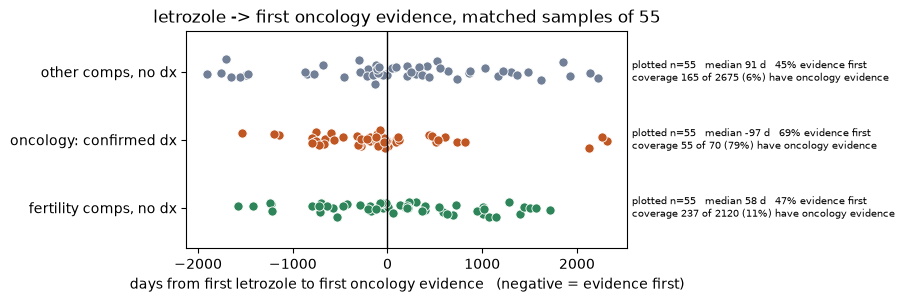

,patients in group,with oncology evidence,coverage %,plotted n,median days,p25,p75,evidence first %
lane,,,,,,,,
"fertility comps, no dx",2120,237,11.0,55,58.0,-358.0,659.0,47.0
oncology: confirmed dx,70,55,79.0,55,-97.0,-395.0,102.0,69.0
"other comps, no dx",2675,165,6.0,55,91.0,-256.0,688.0,46.0


In [15]:
LANE_NAME = {FERT: 'fertility comps, no dx', ONCO: 'oncology: confirmed dx', BG: 'other comps, no dx'}
onc_first = events[events.tag.isin(eo.ONCOLOGY_TAGS)].groupby('person_id').event_date.min()
gap2      = (onc_first - lz).dt.days.dropna()                      # patients with letrozole AND oncology evidence

by_grp = lambda grp: set(grp_of.index[grp_of == grp]) - case_ids
pools  = {FERT: by_grp(FERT), ONCO: case_ids, BG: by_grp(BG)}      # comparison lanes exclude every confirmed-dx patient
have   = {k: sorted(set(gap2.index) & p) for k, p in pools.items()}
N_PLOT = len(have[ONCO])                                           # match the oncology lane's plotted n
rng    = np.random.default_rng(0)
samp   = {k: (have[k] if k == ONCO else sorted(rng.choice(have[k], min(N_PLOT, len(have[k])), replace=False)))
          for k in lanes}

fig, ax = plt.subplots(figsize=(10.5, 3.2))
for y, k in enumerate(lanes):
    d = gap2.loc[samp[k]]
    ax.scatter(d, y + rng.normal(0, .06, len(d)), s=44, color=GCOL[k], edgecolor='white', linewidth=.6)
    ax.text(1.01, y, f"plotted n={len(d)}   median {d.median():.0f} d   {(d < 0).mean():.0%} evidence first\n"
                     f"coverage {len(have[k])} of {len(pools[k])} ({len(have[k]) / len(pools[k]):.0%}) have oncology evidence",
            transform=ax.get_yaxis_transform(), va='center', fontsize=7.5)
ax.axvline(0, c='k', lw=1)
ax.set_yticks(range(len(lanes))); ax.set_yticklabels([LANE_NAME[k] for k in lanes]); ax.set_ylim(-.6, len(lanes) - .4)
ax.set_xlabel('days from first letrozole to first oncology evidence   (negative = evidence first)')
ax.set_title(f'letrozole -> first oncology evidence, matched samples of {N_PLOT}')
fig.subplots_adjust(left=.22, right=.64, bottom=.2); plt.show()

rows = []
for k in lanes:
    d = gap2.loc[samp[k]]
    rows.append({'lane': LANE_NAME[k], 'patients in group': len(pools[k]), 'with oncology evidence': len(have[k]),
                 'coverage %': round(len(have[k]) / len(pools[k]) * 100, 1), 'plotted n': len(d),
                 'median days': d.median(), 'p25': d.quantile(.25), 'p75': d.quantile(.75),
                 'evidence first %': round((d < 0).mean() * 100, 1)})
display(pd.DataFrame(rows).set_index('lane').round(0))

## 4 · Trajectory graph — the readable artifact

Aggregate consecutive transitions into a weighted directed graph. This is close to the UI
sketch from the review, but derived from observed transitions rather than a model's guess
about the next event.

5238 letrozole patients
20 nodes, 138 edges
nodes per group: {'background': 7, 'anchor': 1, 'fertility': 9, 'oncology': 3}


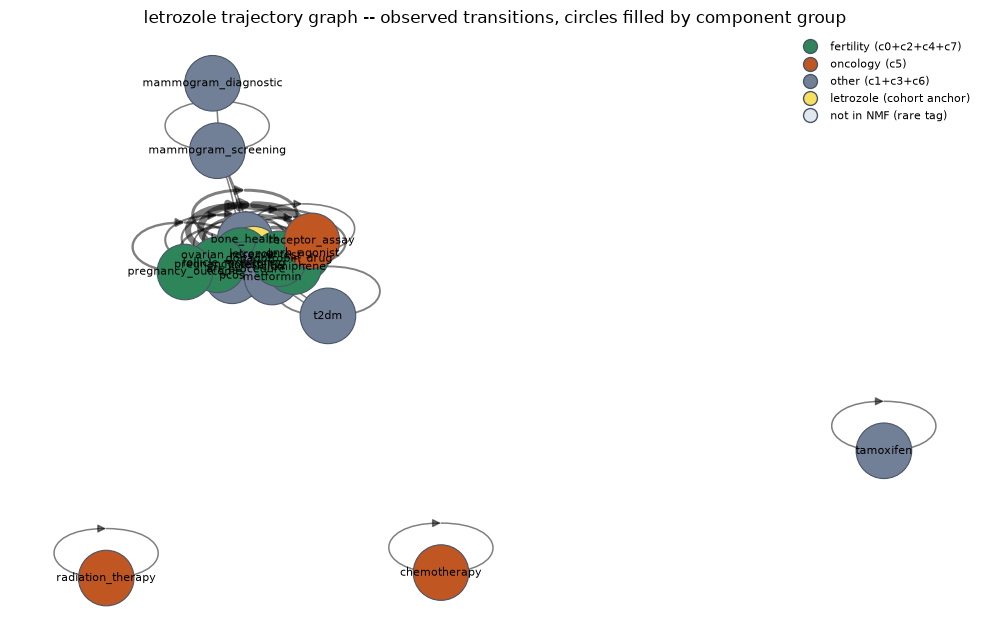

In [16]:
import networkx as nx

# every curated codeset tag (codesets.yaml via eo); the raw per-product codes would swamp the graph
FOCUS = set(eo.CODESETS)

db_lz_g = [[c for c in seqs[p] if c in FOCUS] for p in pids if 'letrozole' in seqs[p]]
print(f"{len(db_lz_g)} letrozole patients")

cnt = collections.Counter()
for s in db_lz_g:
    for u, v in zip(s, s[1:]):
        cnt[(u, v)] += 1
G = nx.DiGraph()
for (u, v), w in cnt.items():
    if w >= max(5, int(0.02 * len(db_lz_g))):
        G.add_edge(u, v, weight=w)
print(G.number_of_nodes(), "nodes,", G.number_of_edges(), "edges")

# Fill colour = the component group that owns the tag's NMF loading (its share of the tag's total
# loading; fertility is summed over its 4 components). letrozole is the cohort anchor, so it is not in
# the NMF; tags dropped by the prevalence floor are not in H either.
grp_comps = {g: [k for k, v in COMP.items() if v[2] == g] for g in GCOL}
def owner_group(tag):
    if tag == 'letrozole':
        return 'anchor'
    if tag not in H.columns or H[tag].sum() == 0:
        return 'not in NMF'
    share = {g: H.loc[ks, tag].sum() / H[tag].sum() for g, ks in grp_comps.items()}
    return max(share, key=share.get)
NODE_COL = {**GCOL, 'anchor': '#f6e05e', 'not in NMF': '#e2e8f0'}
node_grp = {n: owner_group(n) for n in G.nodes()}
print("nodes per group:", dict(collections.Counter(node_grp.values())))

plt.figure(figsize=(10, 6.5))
pos = nx.spring_layout(G, seed=3, k=1.1)
w   = np.array([G[u][v]['weight'] for u, v in G.edges()], dtype=float)
nx.draw_networkx_nodes(G, pos, node_size=1600, node_color=[NODE_COL[node_grp[n]] for n in G.nodes()],
                       edgecolors='#4a5568', linewidths=.8)
nx.draw_networkx_labels(G, pos, font_size=8)
nx.draw_networkx_edges(G, pos, width=1 + 4 * w / w.max(), alpha=.5,
                       arrowsize=12, connectionstyle='arc3,rad=0.08')
from matplotlib.lines import Line2D
plt.legend(handles=[Line2D([0], [0], marker='o', ls='', markersize=10, markerfacecolor=col,
                           markeredgecolor='#4a5568', label=lab)
                    for col, lab in [(GCOL[FERT], GNAME[FERT]), (GCOL[ONCO], GNAME[ONCO]), (GCOL[BG], GNAME[BG]),
                                     (NODE_COL['anchor'], 'letrozole (cohort anchor)'),
                                     (NODE_COL['not in NMF'], 'not in NMF (rare tag)')]],
           loc='upper right', fontsize=8, frameon=False)
plt.title('letrozole trajectory graph -- observed transitions, circles filled by component group')
plt.axis('off'); plt.tight_layout(); plt.show()

Read the arms against the NMF components: a fertility-treatment arm (clomiphene,
gonadotropins, ART), a pregnancy arm (pregnancy test, pregnancy outcome), and a much thinner
oncology arm (receptor assay, biopsy, chemotherapy, mastectomy). Whichever dominates numerically
is the answer — let the graph say which, rather than assuming.

**Circle colours.** Each tag is filled by the component group that owns most of its NMF loading:
green = fertility (c0 + c2 + c4 + c7 together), orange = oncology (c5), grey = other (c1 + c3 + c6).
Yellow is `letrozole` itself (the cohort anchor, not in the NMF); pale grey is a tag too rare to reach
the NMF. A colour is a loading share, not a diagnosis, and a tag shared between groups takes the larger share.